[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L5/BA_L5_paper_t1/BA_L5_paper_t1.ipynb)

# BA_L5_paper_t1: Event Utility of Four Classifiers (Published Table)

*Quantlet of Lecture 5, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Event-level utility U with 95% confidence intervals of four tree-based classifiers (CatBoost, random forest, XGBoost, LightGBM) for six values of the class-weight parameter alpha, on the test period of the stablecoin depeg early-warning study; values from Table 1 of Chaffard, Gaman, Staures, Ginavar, Jheng, Hardle and Pele (2026), Onchain Monitoring of Stablecoin Depeg Risk, working paper.

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

Setup: chart style and colours of the slides, and a `save()` helper that puts one legend below the figure.

In [4]:
import matplotlib
import matplotlib.dates as mdates
from scipy import stats

# the slide charts use matplotlib's default sizes with 10-point text and an 8-point legend
plt.rcParams.update({'font.size': 10, 'axes.labelsize': 'medium', 'axes.titlesize': 'large', 'axes.linewidth': 0.8,
                     'lines.linewidth': 1.5, 'legend.fontsize': 8})
COL = {'USDT': GREEN, 'USDC': BLUE, 'DAI': GOLD}


def save(fig, name, bottom, ncol=3):
    """One legend for all panels below the plot (as on the slide), then save to OUT_PATH and show."""
    fig.legend(loc='lower center', ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, bottom, 1, 1))
    save_fig(fig, name)

## What the chart shows

Source: Table 1 of Chaffard, Găman, Staures, Ginavar, Jheng, Härdle & Pele (2026), *Onchain Monitoring of Stablecoin Depeg Risk*, working paper. The values are typed in below; nothing is estimated here.

The paper predicts a breach of 15 basis points by USDC priced in USDT, within the next 24 hours, on the Uniswap V3 USDC/USDT pool (hourly, January 2022 – May 2026), with on-chain features.
Four tree-based classifiers (CatBoost, random forest, XGBoost, LightGBM) are trained with a class-weight parameter $\alpha$; each alarm is scored on the test period with the event-level utility

$$ U = \frac{1}{|E|}\sum_{e \in E} v(\ell_e) - 0.05\,F_m , $$

where $v(\ell_e)$ is the credit for an alert $\ell_e$ hours before event $e$ and $F_m$ the number of false alerts per month.
The chart shows $U$ with its 95% confidence interval (CI) for every model and $\alpha$.

In [5]:
T1 = {  # model: [(alpha, U, lower CI, upper CI, recall, false alerts per month)], Table 1 of the paper
    'CatBoost': [(0.1, .208, .142, .279, .568, 2.30), (0.3, .303, .229, .381, .723, 2.50), (0.5, .149, .084, .206, .517, 2.33),
                 (1, .281, .204, .363, .746, 3.07), (1.5, .183, .110, .261, .589, 3.10), (2, .226, .157, .298, .685, 2.70)],
    'Random forest': [(0.1, .180, .118, .243, .410, 0.97), (0.3, .071, .018, .127, .160, 0.76), (0.5, .233, .150, .308, .489, 1.45),
                      (1, .222, .152, .291, .515, 1.79), (1.5, .111, .049, .178, .305, 1.49), (2, .170, .100, .241, .437, 1.93)],
    'XGBoost': [(0.1, -.049, -.069, -.033, 0, .99), (0.3, .002, -.035, .037, .186, 1.59), (0.5, .076, .012, .133, .516, 3.46),
                (1, .101, .029, .182, .544, 3.73), (1.5, -.040, -.091, .014, .206, 3.28), (2, -.055, -.090, -.020, .055, 1.75)],
    'LightGBM': [(0.1, -.071, -.096, -.047, .030, 1.60), (0.3, -.037, -.064, -.010, .054, 1.19), (0.5, -.124, -.158, -.090, .032, 2.69),
                 (1, -.096, -.143, -.041, .105, 3.05), (1.5, .010, -.035, .060, .118, 1.34), (2, -.093, -.136, -.045, .095, 2.96)]}

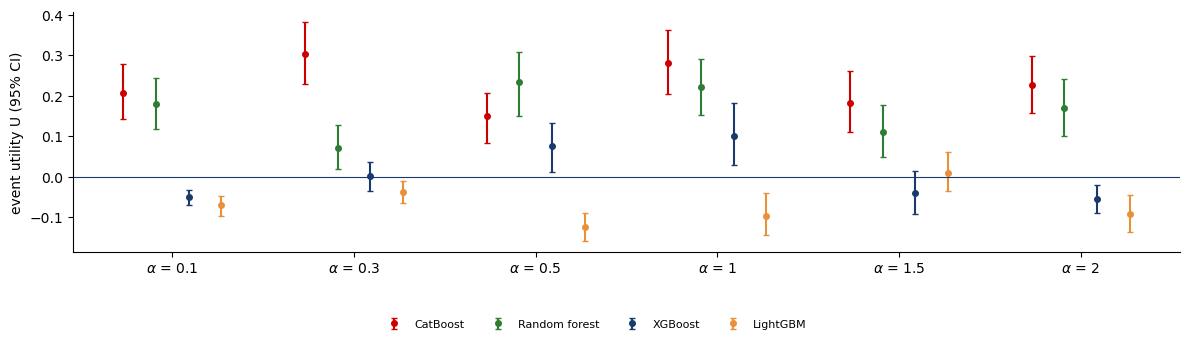

In [6]:
fig, ax = plt.subplots(figsize=(12, 3.4))
off = {'CatBoost': -0.27, 'Random forest': -0.09, 'XGBoost': 0.09, 'LightGBM': 0.27}
cols = {'CatBoost': RED, 'Random forest': GREEN, 'XGBoost': BLUE, 'LightGBM': BTC}
for mname, rows_ in T1.items():
    a = np.arange(6) + off[mname]
    Uv, lo_, hi_ = (np.array([r_[j] for r_ in rows_]) for j in (1, 2, 3))
    ax.errorbar(a, Uv, yerr=[Uv - lo_, hi_ - Uv], fmt='o', color=cols[mname], capsize=2, ms=4, label=mname)
ax.axhline(0, color=BLUE, lw=0.8)
ax.set_xticks(range(6)); ax.set_xticklabels([r'$\alpha$ = ' + str(r_[0]) for r_ in T1['CatBoost']])
ax.set_ylabel('event utility U (95% CI)')
save(fig, 'ba_l5_paper_t1', 0.13, ncol=4)

## Key numbers (Table 1 of the paper)

In [7]:
tab = pd.DataFrame([{'model': m, 'alpha': r_[0], 'U': r_[1], 'CI lower': r_[2], 'CI upper': r_[3], 'recall': r_[4],
                     'false alerts per month': r_[5]} for m, rows_ in T1.items() for r_ in rows_]).set_index(['model', 'alpha'])
tab

U  CI lower  CI upper  recall  false alerts per month
model         alpha                                                           
CatBoost      0.1    0.208     0.142     0.279   0.568                    2.30
              0.3    0.303     0.229     0.381   0.723                    2.50
              0.5    0.149     0.084     0.206   0.517                    2.33
              1.0    0.281     0.204     0.363   0.746                    3.07
              1.5    0.183     0.110     0.261   0.589                    3.10
              2.0    0.226     0.157     0.298   0.685                    2.70
Random forest 0.1    0.180     0.118     0.243   0.410                    0.97
              0.3    0.071     0.018     0.127   0.160                    0.76
              0.5    0.233     0.150     0.308   0.489                    1.45
              1.0    0.222     0.152     0.291   0.515                    1.79
              1.5    0.111     0.049     0.178   0.305                    1.49
              2.0    0.170     0.100     0.241   0.437                    1.93
XGBoost       0.1   -0.049    -0.069    -0.033   0.000                    0.99
              0.3    0.002    -0.035     0.037   0.186                    1.59
              0.5    0.076     0.012     0.133   0.516                    3.46
              1.0    0.101     0.029     0.182   0.544                    3.73
              1.5   -0.040    -0.091     0.014   0.206                    3.28
              2.0   -0.055    -0.090    -0.020   0.055                    1.75
LightGBM      0.1   -0.071    -0.096    -0.047   0.030                    1.60
              0.3   -0.037    -0.064    -0.010   0.054                    1.19
              0.5   -0.124    -0.158    -0.090   0.032                    2.69
              1.0   -0.096    -0.143    -0.041   0.105                    3.05
              1.5    0.010    -0.035     0.060   0.118                    1.34
              2.0   -0.093    -0.136    -0.045   0.095                    2.96

**How to read it:** the best alarm, CatBoost with $\alpha = 0.3$, detects 72% of the test events with 2.5 false alerts a month ($U = 0.303$); the budget of 2 false alerts a month was imposed on validation.
XGBoost and LightGBM have utilities near or below zero for most $\alpha$: the false alerts cost more than the timely detections earn.